## RandomForestClassifier

### Data Preparation and Train-Test Split

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

data = pd.read_csv('tensor_features.csv')
print(data.head())

X = data[['xx', 'yy', 'xy', 'normalized_diff']]
y = data['label']

data['label'] = data['label'].astype(int) # label modyfication z bool('True' or 'False') na int (0 or 1)
print(data.head())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


   id  label           xx           yy           xy  normalized_diff
0  10   True  2251.879460  4467.406612  -511.955541        -0.329727
1  11   True  2971.936804  3971.943088  -885.822012        -0.144013
2  12  False  1833.841218  3709.724540  -831.472858        -0.338389
3  13   True  2412.707474  6169.769803  -880.450924        -0.437760
4  14   True  2262.447856  4812.389570 -1298.565125        -0.360424
   id  label           xx           yy           xy  normalized_diff
0  10      1  2251.879460  4467.406612  -511.955541        -0.329727
1  11      1  2971.936804  3971.943088  -885.822012        -0.144013
2  12      0  1833.841218  3709.724540  -831.472858        -0.338389
3  13      1  2412.707474  6169.769803  -880.450924        -0.437760
4  14      1  2262.447856  4812.389570 -1298.565125        -0.360424


### Training and optimizing a classification pipeline &
### Building the RandomForestClassifier model with optimal hyperparameters identified through GridSearchCV

In [15]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])

param_grid = {
    'model__n_estimators': [60, 70, 80, 90, 100, 120, 150],
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [None, 10, 20],
    'model__bootstrap': [True, False],
    'model__class_weight': ['balanced', 'balanced_subsample', {0: 15, 1: 5}]
}

final_model = GridSearchCV(pipeline, param_grid, cv=5)
final_model.fit(X_train, y_train)

print("Optimal hyperparameters found:", final_model.best_params_)

print("\nModel evaluation on test data with the best parameters:")
y_pred_final = final_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred_final)

print(f"\nModel accuracy: {accuracy:.2f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred_final))

Optimal hyperparameters found: {'model__bootstrap': True, 'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': None, 'model__n_estimators': 60}

Model evaluation on test data with the best parameters:

Model accuracy: 0.75

Classification report:
              precision    recall  f1-score   support

       False       1.00      0.50      0.67         4
        True       0.67      1.00      0.80         4

    accuracy                           0.75         8
   macro avg       0.83      0.75      0.73         8
weighted avg       0.83      0.75      0.73         8



### Feature importances

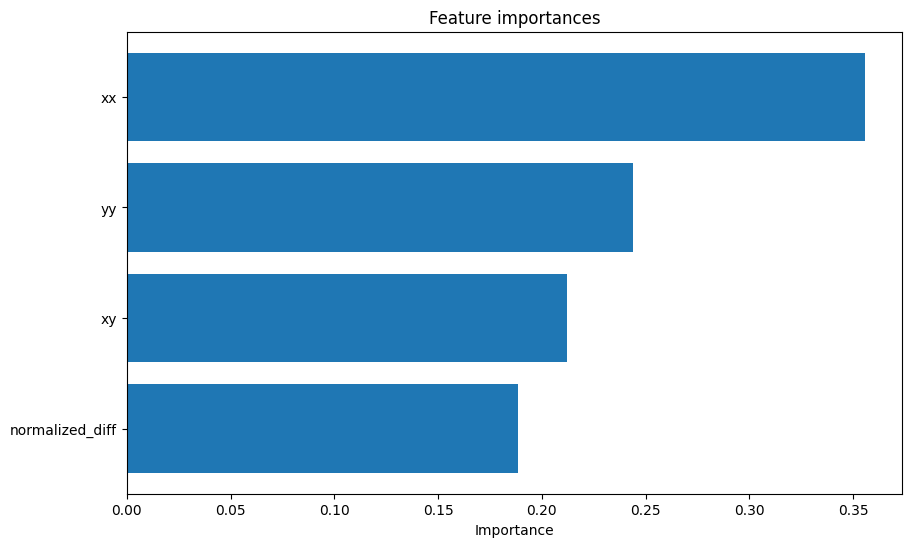

In [14]:
import matplotlib.pyplot as plt

best_model = final_model.best_estimator_
rf_model = best_model.named_steps['model']
importances = rf_model.feature_importances_

features = X.columns
indices = importances.argsort()

plt.figure(figsize=(10, 6))
plt.title("Feature importances")
plt.barh(features[indices], importances[indices], align="center")
plt.xlabel("Importance")
plt.show()

### Model vol. 2 - without normalized_diff

In [22]:
data_vol2 = data.copy()
data_vol2['label'] = data_vol2['label'].astype(int)

X_vol2 = data_vol2[['xx', 'yy', 'xy']]
y_vol2 = data_vol2['label']

X_train_vol2, X_test_vol2, y_train_vol2, y_test_vol2 = train_test_split(X_vol2, y_vol2, test_size=0.2, random_state=42)

model_vol2 = RandomForestClassifier(random_state=42, 
                                    n_estimators=60, 
                                    criterion='gini', 
                                    max_depth=None, 
                                    bootstrap=True, 
                                    class_weight='balanced')

scaler_vol2 = StandardScaler().fit(X_train_vol2)
X_train_scaled_vol2 = scaler_vol2.transform(X_train_vol2)

model_vol2.fit(X_train_scaled_vol2, y_train_vol2)

X_test_scaled_vol2 = scaler_vol2.transform(X_test_vol2)

y_pred_final_vol2 = model_vol2.predict(X_test_scaled_vol2)

accuracy_final_vol2 = accuracy_score(y_test_vol2, y_pred_final_vol2)
print(f"\nModel accuracy: {accuracy_final_vol2:.2f}")
print("\nClassification report:")
print(classification_report(y_test_vol2, y_pred_final_vol2))



Model accuracy: 0.62

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.25      0.40         4
           1       0.57      1.00      0.73         4

    accuracy                           0.62         8
   macro avg       0.79      0.62      0.56         8
weighted avg       0.79      0.62      0.56         8

